#### Configuration
Compare all, last-8 and last-4 steering at both push penalties; existing experiments remain untouched.

In [1]:
from pathlib import Path
from itertools import product
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from IPython.display import display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'llm' / 'model.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
from llm.model import load_model
from llm.steering import LQRSteering, DriftLQRSteering, sample
from llm.trace import trace, completion_metrics
from llm.judge import build_judge, concept_criterion, COHERENCE

RUN = False
MODEL_NAME, CONCEPT, PROMPT = 'Qwen/Qwen3-4B', 'football', 'Once upon a time'
SEED, RANDOM_SEED = 0, 0
DIRECTION_SAMPLES, JACOBIAN_SAMPLES, MAX_CTX = 200, 50, 32
Q, QF, RS, LAST_N = 0.1, 0.1, (1.0, 10.0), (4, 8, None)
LAMBDAS, DRIFT_WEIGHTS, MATCHED_CONCEPT = tuple(range(1, 9)), (0.0, 2.0), (0.75, 0.9)
TRIALS, MAX_NEW_TOKENS, GENERATION_BATCH, TRACE_BATCH = 1000, 96, 500, 100
TEMPERATURE, TOP_P, JUDGE_BATCH, JUDGE_CHUNK = 0.7, 0.95, 256, 2048
OPERATOR_NAMES = ('Identity', 'Mean Jacobian', 'Random', 'Steering DMD')
COLORS, CMAPS = {0.0: 'tab:blue', 2.0: 'tab:orange'}, {0.0: 'Blues', 2.0: 'Oranges'}
MODEL_DIR = REPO_ROOT / 'artifacts' / MODEL_NAME.rsplit('/', 1)[-1].lower()
E_PATH = MODEL_DIR / '01_concept_direction_steering' / f'E_{CONCEPT}_n{DIRECTION_SAMPLES}_seed{SEED}.pt'
A_PATH = MODEL_DIR / '02_qwen3_model_ablation' / f'A_{CONCEPT}_n{JACOBIAN_SAMPLES}_ctx{MAX_CTX}_seed{SEED}.pt'
DMD_PATH = MODEL_DIR / '04_linear_prediction' / f'steering_dmd_{CONCEPT}.pt'
RUN_DIR = MODEL_DIR / '03_drift_lqr_ablation' / f'{CONCEPT}_n{TRIALS}'
CELL_DIR, VERDICTS_PATH = RUN_DIR / 'cells', RUN_DIR / 'judge_cache.csv'
KEYS, METRICS = ['N', 'R', 'operator', 'drift_weight', 'lambda'], ['along_v', 'change', 'orthogonal', 'push_energy']

/home/dunstan/git/kae-steering/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Sweep grid
Resume completed cells; the unsteered baseline is shared across penalties and layer scopes.

In [2]:
E = torch.load(E_PATH, map_location='cpu', weights_only=True)
num_layers, hidden = E.shape[0] - 1, E.shape[-1]
NS = tuple(num_layers if n is None else n for n in LAST_N)
grid = pd.DataFrame(product(NS, RS, OPERATOR_NAMES, DRIFT_WEIGHTS, LAMBDAS), columns=KEYS)
grid = pd.concat([pd.DataFrame([[0, 0.0, 'Unsteered', 0.0, 0]], columns=KEYS), grid], ignore_index=True)
grid['path'] = [CELL_DIR / f'r{r:g}_n{n}_{name.lower().replace(" ", "_")}_w{w:g}_l{lmbda:g}.csv'
                for n, r, name, w, lmbda in grid.itertuples(index=False, name=None)]
pending = grid.loc[~grid.path.map(Path.exists)]
sample_kwargs = dict(max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P)
CELL_DIR.mkdir(parents=True, exist_ok=True)

#### Model and operators
Reuse the shared direction, Mean Jacobian and rank-selected steering-DMD cache; Random uses notebook 03’s original seed and scaling.

In [3]:
if RUN and not pending.empty:
    tokenizer, model = load_model(MODEL_NAME)
    _, nominal = load_model(MODEL_NAME)
    prompt_length = len(tokenizer(PROMPT)['input_ids'])
    A_jac = torch.load(A_PATH, map_location='cpu', weights_only=True)
    cached = torch.load(DMD_PATH, map_location='cpu', weights_only=True)
    if cached['config']['model'] != MODEL_NAME or cached['config']['concept'] != CONCEPT:
        raise ValueError('Steering DMD cache does not match the model and concept')
    if len(cached['factors']) != num_layers:
        raise ValueError('Steering DMD cache has the wrong number of blocks')
    identity = torch.eye(hidden)
    A_dmd = torch.empty_like(A_jac)
    for layer, (left, basis) in enumerate(cached['factors']):
        torch.addmm(identity, left, basis.T, out=A_dmd[layer])
    noise = torch.randn(num_layers, hidden, hidden, generator=torch.Generator().manual_seed(RANDOM_SEED))
    scale = torch.linalg.matrix_norm(A_jac - identity) / torch.linalg.matrix_norm(noise)
    operators = {'Identity': identity.expand(num_layers, -1, -1), 'Mean Jacobian': A_jac,
                 'Random': identity + scale[:, None, None] * noise, 'Steering DMD': A_dmd}
    del noise, cached

#### Completion batches
Seed once per lambda and advance the random stream across generation batches; smaller replay batches bound activation memory.

In [4]:
def collect_cell(controller, settings):
    seed = SEED + max(int(settings['lambda']) - 1, 0)
    torch.manual_seed(seed)
    rows = []
    for start in range(0, TRIALS, GENERATION_BATCH):
        ids = sample(model, tokenizer, PROMPT, min(GENERATION_BATCH, TRIALS - start),
                     controller=controller, lmbda=settings['lambda'], **sample_kwargs)
        for offset in range(0, len(ids), TRACE_BATCH):
            batch = ids[offset:offset + TRACE_BATCH]
            if controller is None:
                metrics = [dict.fromkeys(METRICS, 0.0) for _ in batch]
            else:
                replay = trace(model, controller, settings['lambda'], batch, prompt_length)
                metrics = completion_metrics(replay)
                del replay
            texts = tokenizer.batch_decode(batch[:, prompt_length:], skip_special_tokens=True)
            rows.extend(settings | values | dict(trial=start + offset + i, seed=seed, every=1,
                                                completion=text.strip())
                        for i, (text, values) in enumerate(zip(texts, metrics)))
    return pd.DataFrame(rows)

#### Generate
Use one controller per layer scope, penalty, operator and drift weight; save each completed condition atomically.

In [5]:
if RUN and not pending.empty:
    with tqdm(total=len(grid) * TRIALS, initial=(len(grid) - len(pending)) * TRIALS,
              desc='Generating completions', unit='completion') as progress:
        for (N, R, name, weight), cells in pending.groupby(KEYS[:-1], sort=False):
            if name == 'Unsteered':
                controller = None
            else:
                kwargs = dict(every=1, steer_last_n_layers=N)
                controller = (LQRSteering(model, operators[name], E, Q, R, QF, **kwargs) if weight == 0 else
                              DriftLQRSteering(model, nominal, operators[name], E, Q, R, QF,
                                               drift_weight=weight, **kwargs))
            for values in cells[KEYS + ['path']].itertuples(index=False, name=None):
                settings, path = dict(zip(KEYS, values[:-1])), values[-1]
                progress.set_postfix(N=N, R=R, operator=name, w=weight, lmbda=settings['lambda'])
                frame = collect_cell(controller, settings)
                temporary = path.with_suffix('.tmp')
                frame.to_csv(temporary, index=False)
                temporary.replace(path)
                progress.update(len(frame))
            del controller
    del model, nominal
    gc.collect()
    torch.cuda.empty_cache()

#### Judge
Score each unique completion once; checkpoint both verdicts together and reuse them when resuming.

In [6]:
frames = [pd.read_csv(path, keep_default_na=False) for path in grid.path if path.exists()]
if not frames:
    raise FileNotFoundError('No saved cells yet; set RUN=True to generate this sweep')
results = pd.concat(frames, ignore_index=True)
results.to_csv(RUN_DIR / 'unjudged.csv', index=False)
verdicts = (pd.read_csv(VERDICTS_PATH, keep_default_na=False) if VERDICTS_PATH.exists() else
            pd.DataFrame(columns=['completion', 'concept', 'coherent']))
unique = results[['completion']].drop_duplicates()
unjudged = unique.loc[~unique.completion.isin(verdicts.completion)]
if RUN and not unjudged.empty:
    judge = build_judge(batch_size=JUDGE_BATCH)
    with tqdm(total=len(unique), initial=len(unique) - len(unjudged),
              desc='Judging unique completions', unit='completion') as progress:
        for start in range(0, len(unjudged), JUDGE_CHUNK):
            batch = unjudged.iloc[start:start + JUDGE_CHUNK].copy()
            batch['concept'] = judge(concept_criterion(CONCEPT), PROMPT, batch.completion, desc='Concept')
            batch['coherent'] = judge(COHERENCE, PROMPT, batch.completion, desc='Coherence')
            verdicts = pd.concat([verdicts, batch], ignore_index=True)
            temporary = VERDICTS_PATH.with_suffix('.tmp')
            verdicts.to_csv(temporary, index=False)
            temporary.replace(VERDICTS_PATH)
            progress.update(len(batch))
    del judge
    gc.collect()
    torch.cuda.empty_cache()
results = results.merge(verdicts, on='completion', how='left', validate='many_to_one')
judged = results.dropna(subset=['concept', 'coherent']).copy()
judged[['concept', 'coherent']] = judged[['concept', 'coherent']].astype(bool)
judged['both'] = judged.concept & judged.coherent
judged.to_csv(RUN_DIR / 'results.csv', index=False)

#### Aggregation
Only fully judged cells enter summaries and plots; matched targets require a complete lambda curve and use its first crossing without extrapolation.

In [7]:
means = ['concept', 'coherent', 'both', *METRICS]
summary = judged.groupby(KEYS).agg(**{name: (name, 'mean') for name in means},
                                  median_push_energy=('push_energy', 'median'), n=('concept', 'size')).reset_index()
summary = summary.loc[summary.n.eq(TRIALS)].copy()
for name in ('concept', 'coherent', 'both'):
    summary[f'{name}_se'] = np.sqrt(summary[name] * (1 - summary[name]) / summary.n)
summary.to_csv(RUN_DIR / 'summary.csv', index=False)

def first_crossing(curve, target):
    curve = curve.sort_values('lambda').reset_index(drop=True)
    columns = ['lambda', 'coherent', 'median_push_energy', 'orthogonal', 'along_v']
    missing = pd.Series({name: np.nan for name in columns})
    reached = np.flatnonzero(curve.concept.to_numpy() >= target)
    if len(curve) != len(LAMBDAS) or not len(reached):
        return missing
    i = reached[0]
    high = curve.iloc[i]
    if high.concept == target:
        return high[columns]
    if i == 0:
        return missing
    low = curve.iloc[i - 1]
    fraction = (target - low.concept) / (high.concept - low.concept)
    return low[columns] + fraction * (high[columns] - low[columns])

#### Matched concept summary
Compare semantic success at 75% and 90% concept rate, rather than treating equal activation shift as equal semantic steering.

In [8]:
rows = []
for values, curve in summary.loc[summary.N.gt(0)].groupby(KEYS[:-1]):
    for target in MATCHED_CONCEPT:
        rows.append(dict(zip(KEYS[:-1], values)) | {'target_concept': target}
                    | first_crossing(curve, target).to_dict())
matched = pd.DataFrame(rows, columns=[*KEYS[:-1], 'target_concept', 'lambda',
                                    'coherent', 'median_push_energy', 'orthogonal', 'along_v'])
matched.to_csv(RUN_DIR / 'matched.csv', index=False)
display(matched.pivot(index=['R', 'N', 'operator', 'target_concept'], columns='drift_weight',
                      values=['coherent', 'median_push_energy']).round(3))

coherent        median_push_energy       
drift_weight                              0.0    2.0                0.0    2.0
R    N  operator      target_concept                                          
1.0  4  Identity      0.75              0.967  0.967              0.043  0.043
                      0.90              0.959  0.960              0.057  0.058
        Mean Jacobian 0.75              0.967  0.966              0.070  0.060
                      0.90              0.945  0.957              0.085  0.073
        Random        0.75              0.973  0.971              0.045  0.047
                      0.90              0.968  0.970              0.061  0.063
        Steering DMD  0.75              0.972  0.971              0.062  0.048
                      0.90              0.964  0.966              0.079  0.061
     8  Identity      0.75              0.969  0.971              0.033  0.061
                      0.90              0.962  0.963              0.043  0.086
        Mean Jacobian 0.75              0.942  0.972              0.037  0.081
                      0.90              0.932  0.955              0.042  0.121
        Random        0.75              0.957  0.967              0.038  0.070
                      0.90              0.945  0.965              0.047  0.099
        Steering DMD  0.75              0.964  0.971              0.041  0.072
                      0.90              0.953  0.963              0.050  0.101
     36 Identity      0.75                NaN  0.975                NaN  0.188
                      0.90              0.865  0.970              0.029  0.261
        Mean Jacobian 0.75                NaN  0.978                NaN  0.158
                      0.90              0.712  0.967              0.029  0.233
        Random        0.75                NaN  0.973                NaN  0.299
                      0.90              0.901  0.968              0.032  0.436
        Steering DMD  0.75                NaN  0.970                NaN  3.143
                      0.90                NaN  0.964                NaN  3.431
10.0 4  Identity      0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
        Mean Jacobian 0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
        Random        0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
        Steering DMD  0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
     8  Identity      0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
        Mean Jacobian 0.75              0.833  0.943              0.035  0.042
                      0.90                NaN  0.910                NaN  0.051
        Random        0.75                NaN    NaN                NaN    NaN
                      0.90                NaN    NaN                NaN    NaN
        Steering DMD  0.75              0.936  0.953              0.057  0.056
                      0.90              0.910    NaN              0.075    NaN
     36 Identity      0.75              0.889  0.955              0.021  0.049
                      0.90              0.800  0.923              0.030  0.079
        Mean Jacobian 0.75              0.796  0.962              0.015  0.030
                      0.90              0.462  0.924              0.022  0.043
        Random        0.75              0.878  0.955              0.036  0.136
                      0.90              0.821  0.919              0.046  0.201
        Steering DMD  0.75              0.926  0.958              0.057  1.117
                      0.90              0.802  0.926              0.082  1.346

#### Coherence versus concept
One figure per penalty, one row per layer scope, and only cancellation off/on within each operator panel.

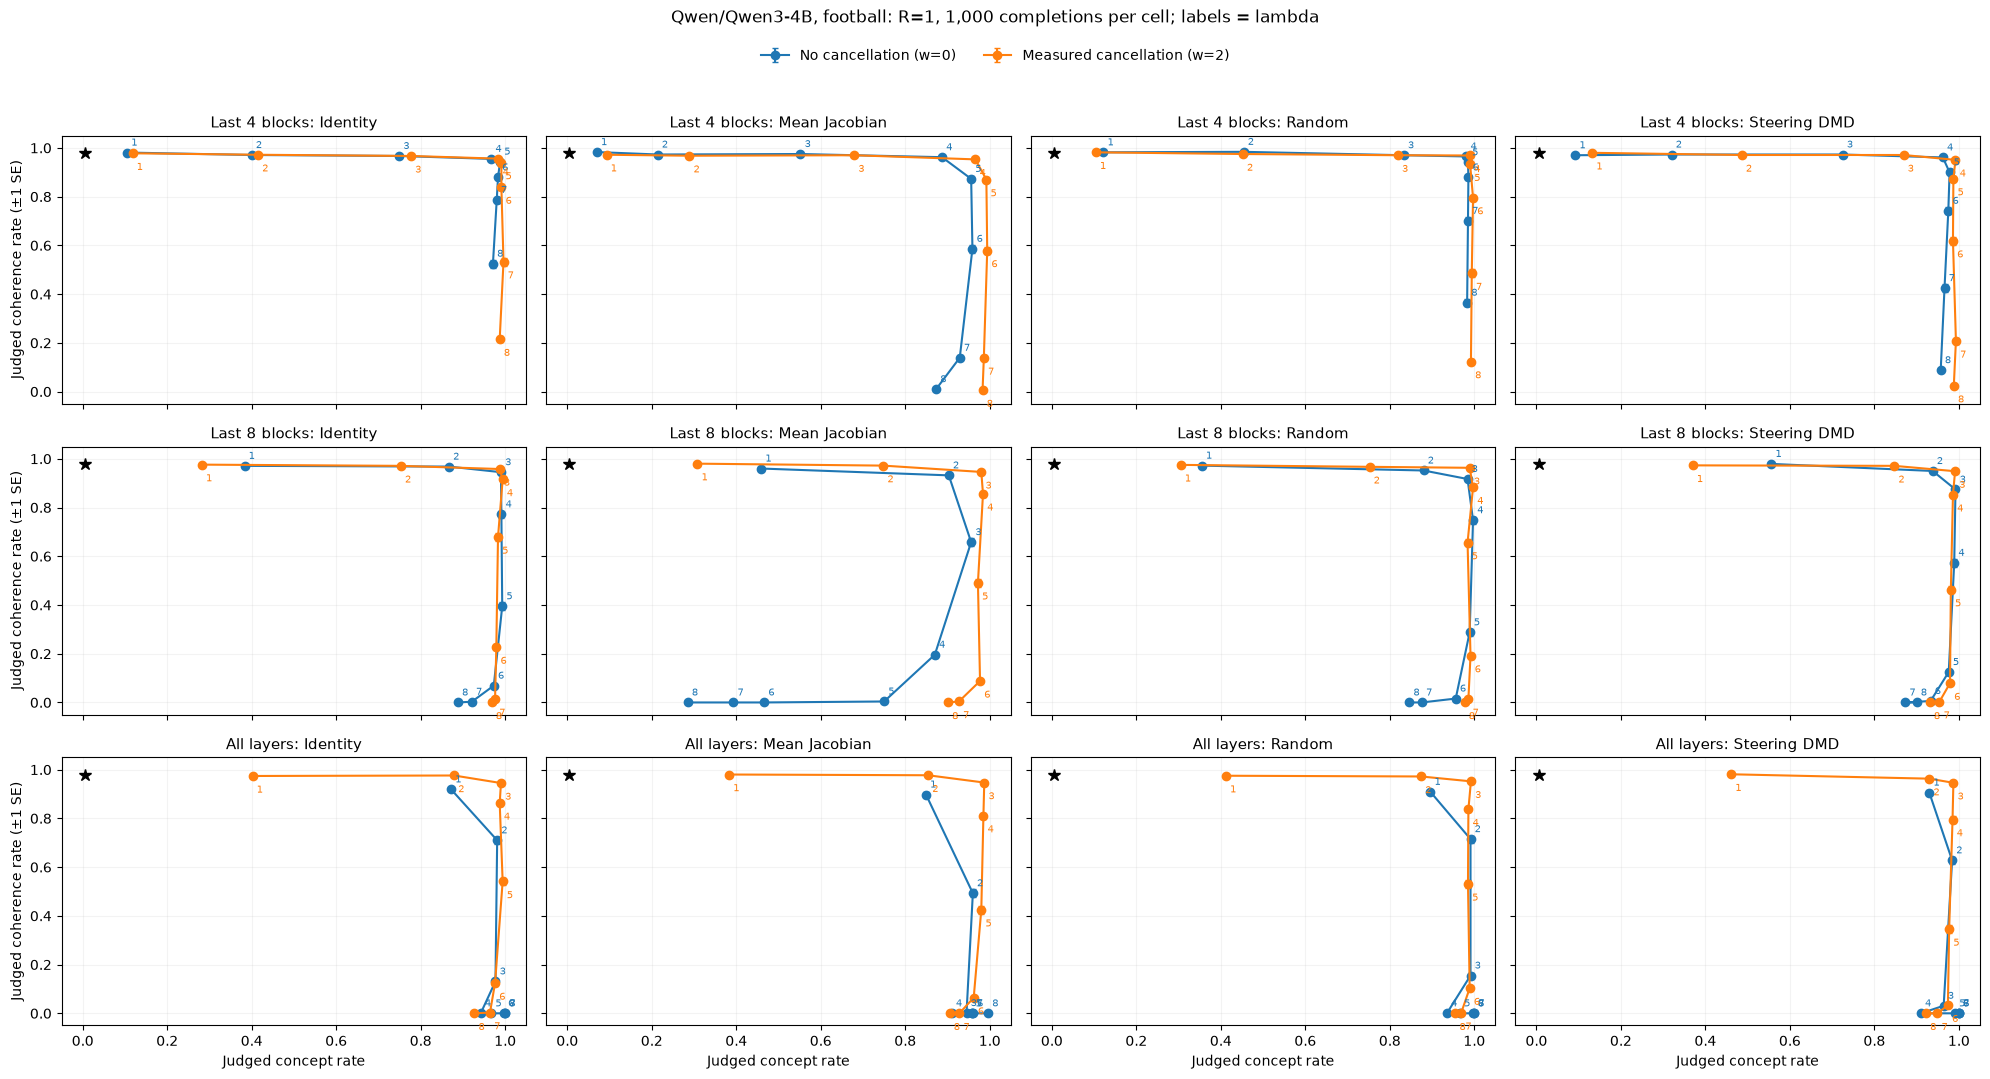

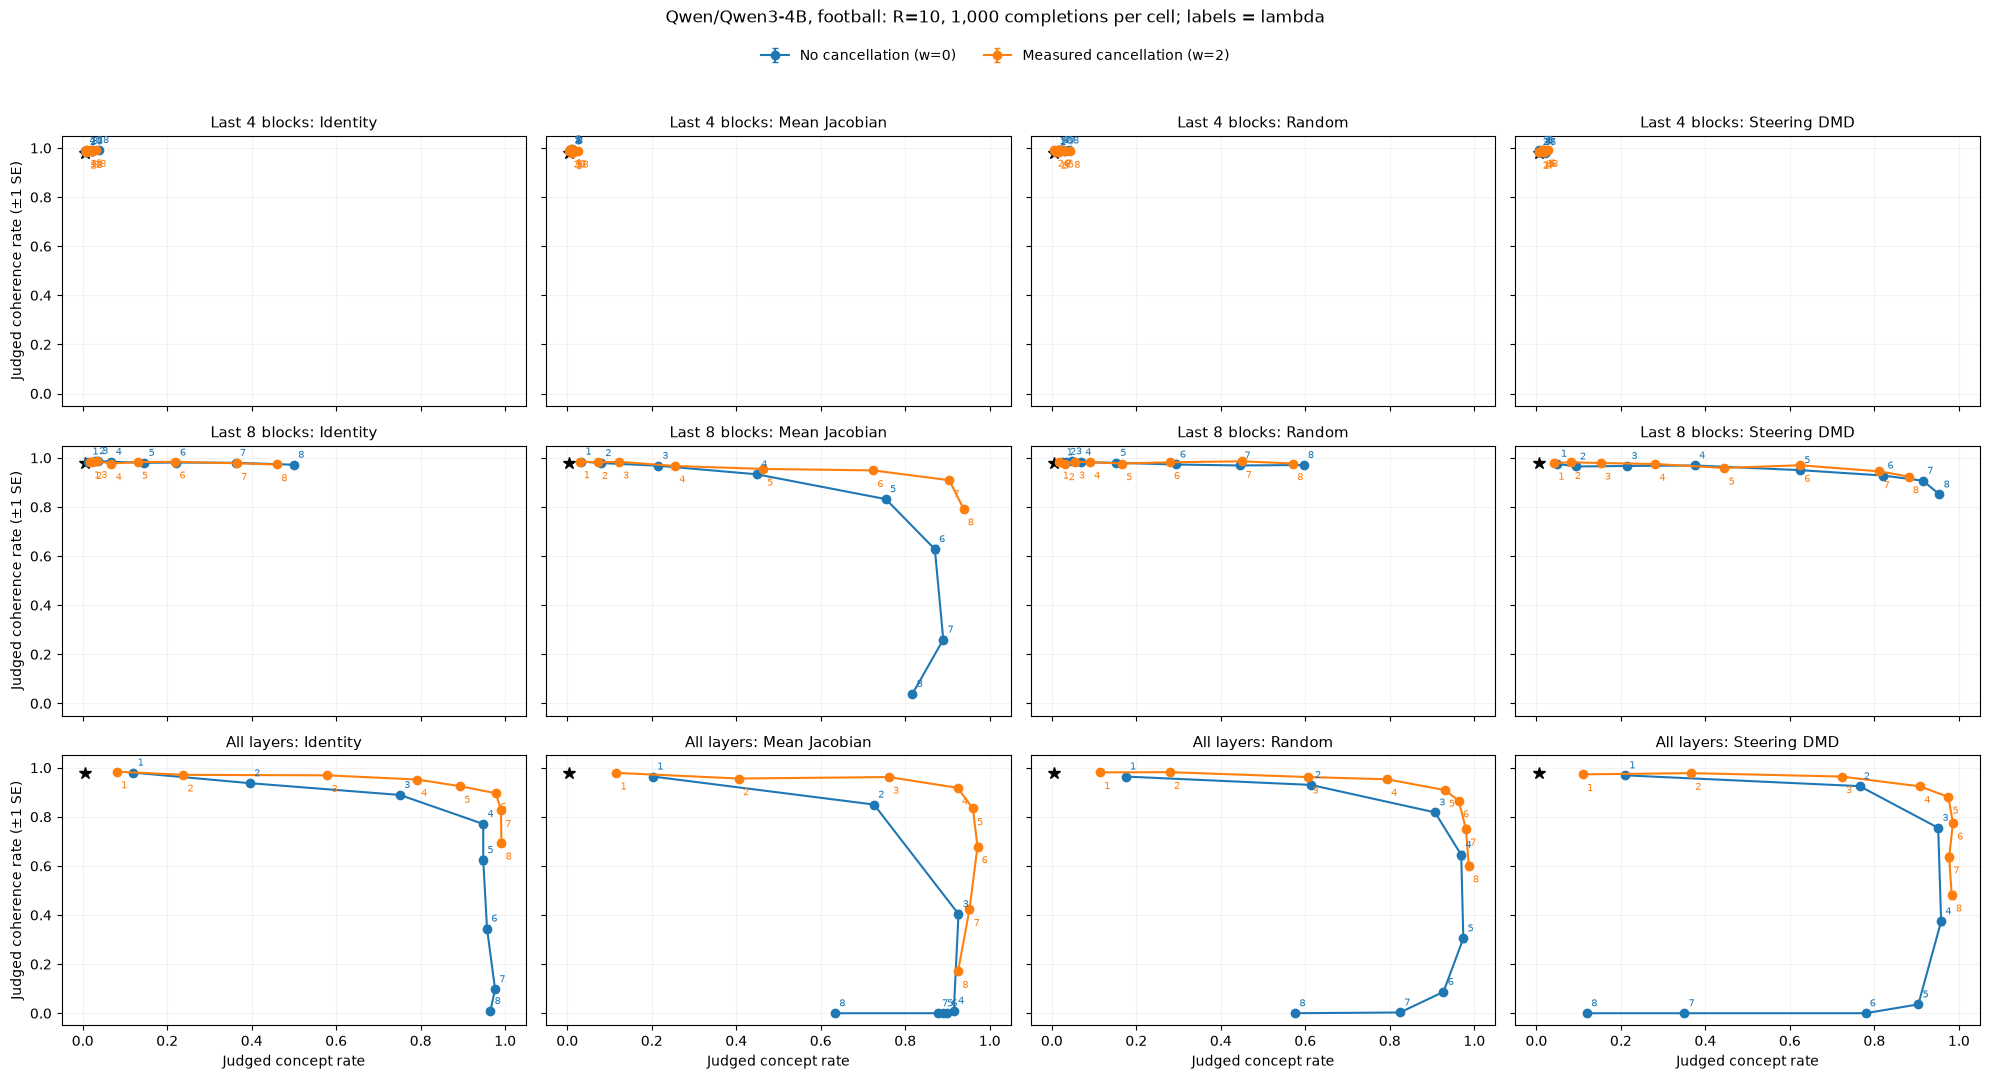

In [9]:
baseline = summary.loc[summary.operator.eq('Unsteered')]
for R in RS:
    fig, axes = plt.subplots(len(NS), len(OPERATOR_NAMES), figsize=(5 * len(OPERATOR_NAMES), 3.6 * len(NS)),
                             sharex=True, sharey=True, squeeze=False)
    for row, N in zip(axes, NS):
        scope = 'All layers' if N == num_layers else f'Last {N} blocks'
        for ax, name in zip(row, OPERATOR_NAMES):
            panel = summary.loc[summary.R.eq(R) & summary.N.eq(N) & summary.operator.eq(name)]
            for weight, curve in panel.groupby('drift_weight'):
                curve = curve.sort_values('lambda')
                label = 'No cancellation (w=0)' if weight == 0 else f'Measured cancellation (w={weight:g})'
                ax.errorbar(curve.concept, curve.coherent, yerr=curve.coherent_se, marker='o', capsize=2,
                            color=COLORS[weight], label=label)
                for concept, coherent, lmbda in curve[['concept', 'coherent', 'lambda']].itertuples(index=False, name=None):
                    ax.annotate(f'{lmbda:g}', (concept, coherent), fontsize=7, color=COLORS[weight],
                                xytext=(3, 5 if weight == 0 else -12), textcoords='offset points')
            ax.plot(baseline.concept, baseline.coherent, 'k*', ms=9)
            ax.set_title(f'{scope}: {name}', fontsize=11)
            ax.grid(alpha=0.15)
    for ax in axes[-1]:
        ax.set_xlabel('Judged concept rate')
    for ax in axes[:, 0]:
        ax.set_ylabel('Judged coherence rate (±1 SE)')
    axes[0, 0].set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.97), ncol=2, frameon=False)
    fig.suptitle(f'{MODEL_NAME}, {CONCEPT}: R={R:g}, {TRIALS:,} completions per cell; labels = lambda', y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(RUN_DIR / f'concept_coherence_r{R:g}.png', dpi=150)
    plt.show()

#### Off-concept change versus concept shift
Separate layer-scope rows; dot darkness represents coherence, dot area represents concept rate, and blue/orange distinguish cancellation off/on.

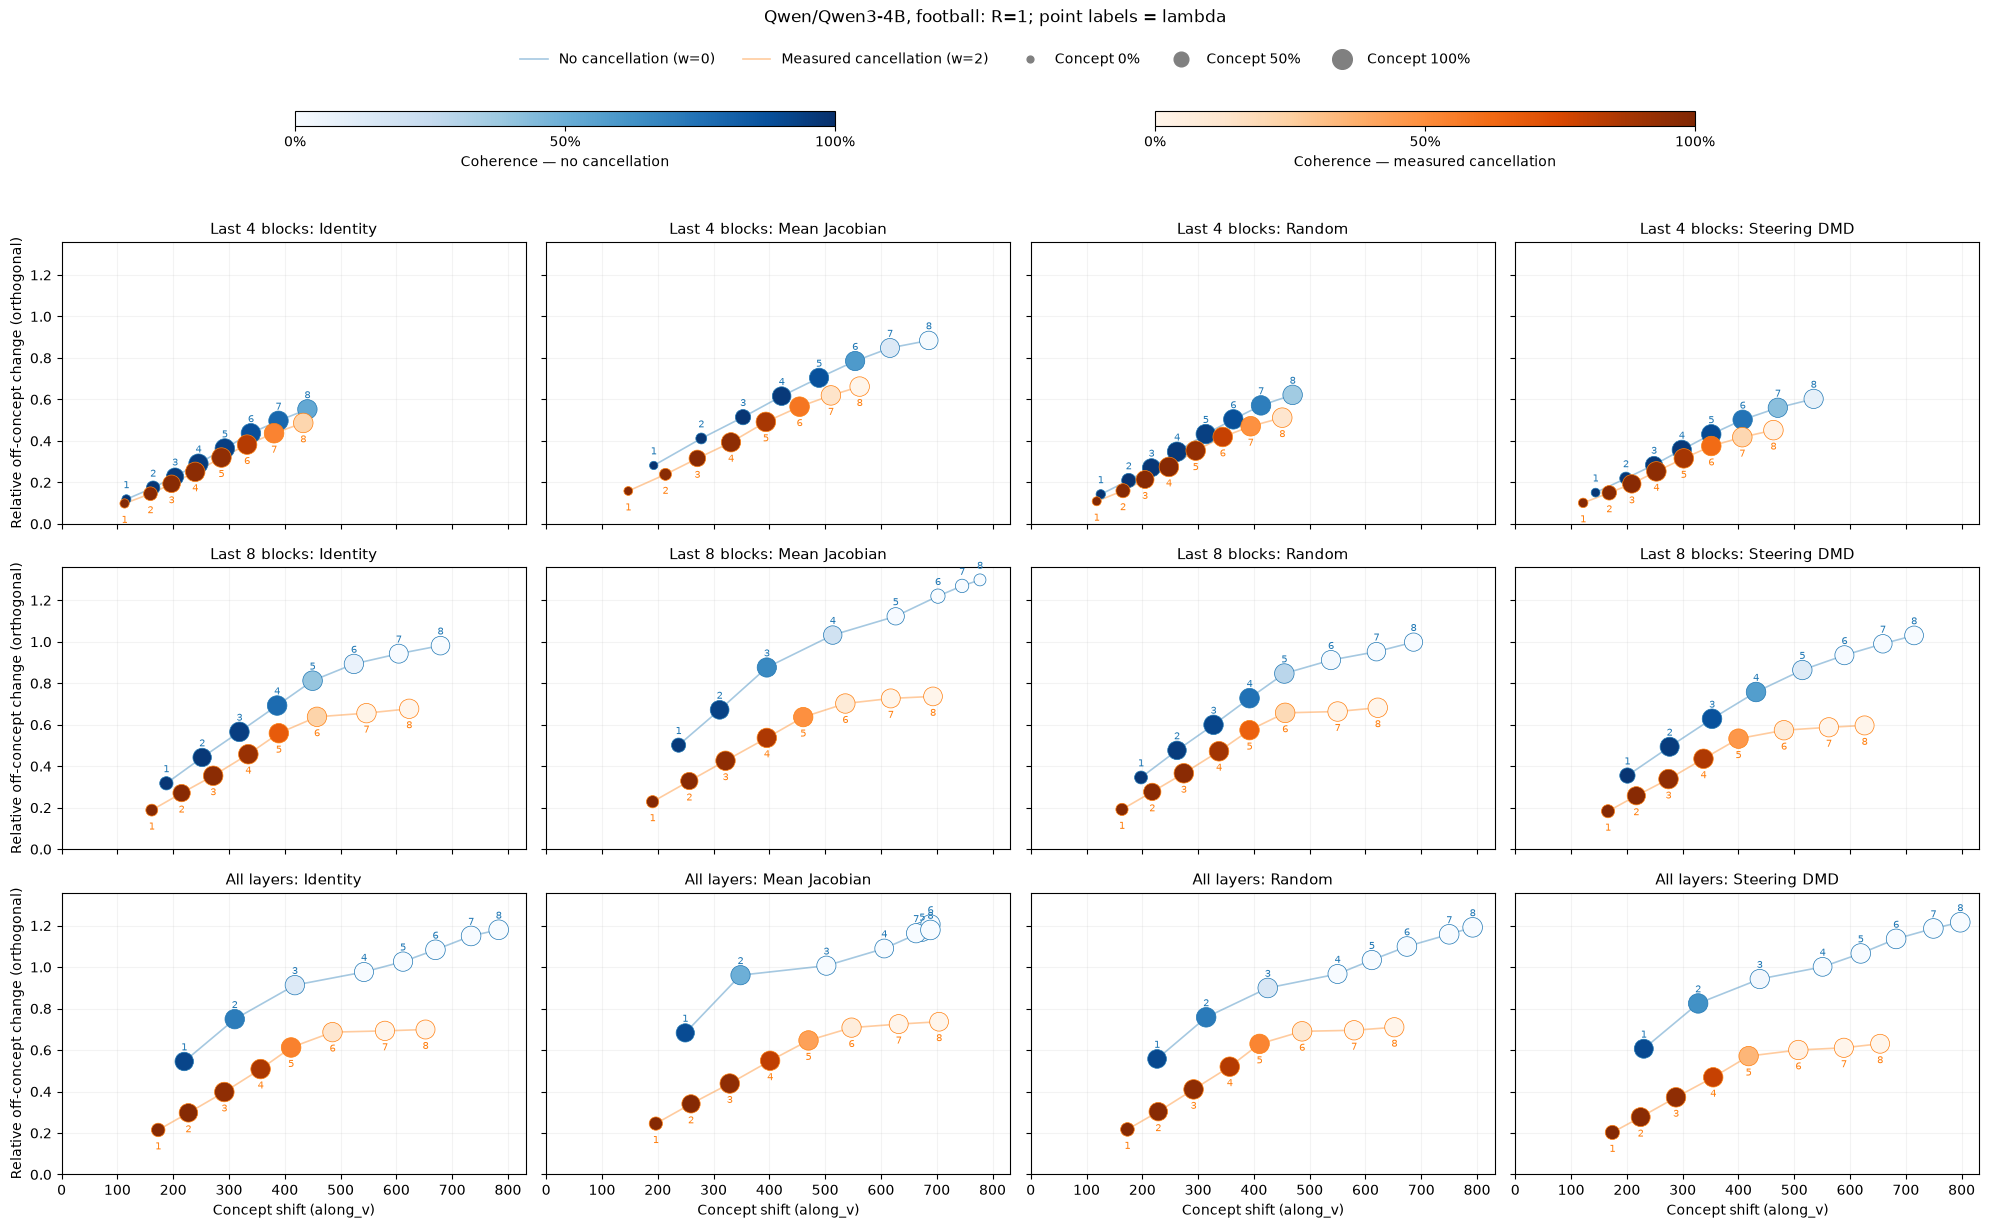

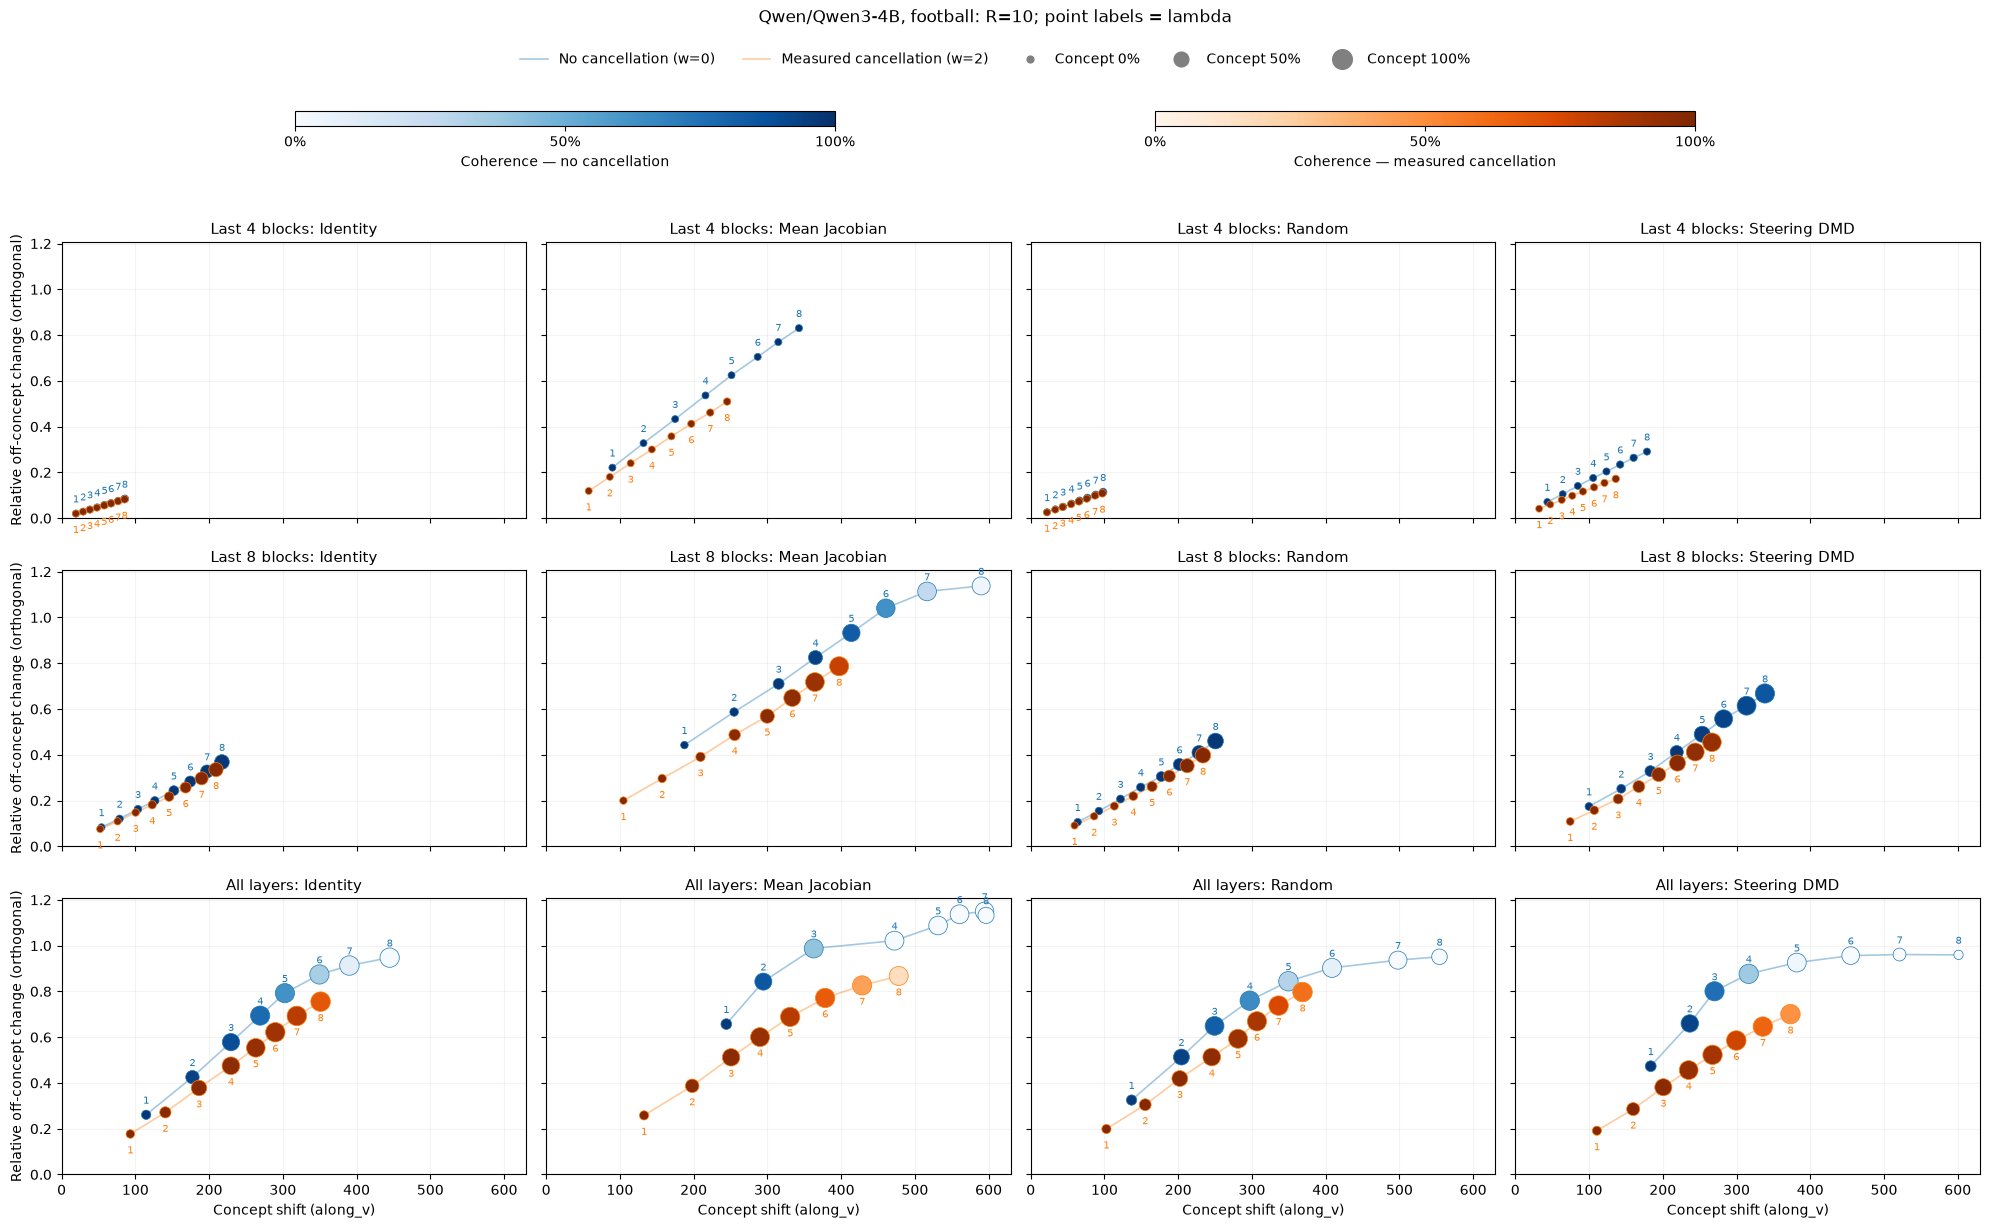

In [10]:
for R in RS:
    fig, axes = plt.subplots(len(NS), len(OPERATOR_NAMES), figsize=(5 * len(OPERATOR_NAMES), 4.1 * len(NS)),
                             sharex=True, sharey=True, squeeze=False)
    for row, N in zip(axes, NS):
        scope = 'All layers' if N == num_layers else f'Last {N} blocks'
        for ax, name in zip(row, OPERATOR_NAMES):
            panel = summary.loc[summary.R.eq(R) & summary.N.eq(N) & summary.operator.eq(name)]
            for weight, curve in panel.groupby('drift_weight'):
                curve = curve.sort_values('lambda')
                label = 'No cancellation (w=0)' if weight == 0 else f'Measured cancellation (w={weight:g})'
                ax.plot(curve.along_v, curve.orthogonal, color=COLORS[weight], linewidth=1.2, alpha=0.4, label=label)
                ax.scatter(curve.along_v, curve.orthogonal, s=24 + 176 * curve.concept, c=curve.coherent,
                           cmap=CMAPS[weight], vmin=0, vmax=1, edgecolors=COLORS[weight], linewidths=0.5, zorder=3)
                for along, orthogonal, lmbda in curve[['along_v', 'orthogonal', 'lambda']].itertuples(index=False, name=None):
                    ax.annotate(f'{lmbda:g}', (along, orthogonal), color=COLORS[weight], fontsize=7,
                                xytext=(0, 8 if weight == 0 else -14), ha='center', textcoords='offset points')
            ax.set_title(f'{scope}: {name}', fontsize=11)
            ax.grid(alpha=0.15)
    for ax in axes[-1]:
        ax.set_xlabel('Concept shift (along_v)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Relative off-concept change (orthogonal)')
    axes[0, 0].set(xlim=(0, None), ylim=(0, None))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles += [plt.Line2D([], [], linestyle='none', marker='o', color='0.5',
                           markersize=np.sqrt(24 + 176 * rate), label=f'Concept {rate:.0%}') for rate in (0, 0.5, 1)]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.97), ncol=5, frameon=False)
    fig.suptitle(f'{MODEL_NAME}, {CONCEPT}: R={R:g}; point labels = lambda', y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    for i, (weight, cmap) in enumerate(CMAPS.items()):
        bar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=cmap),
                           cax=fig.add_axes((0.15 + 0.43 * i, 0.90, 0.27, 0.012)), orientation='horizontal')
        bar.set_label(f'Coherence — {"no cancellation" if weight == 0 else "measured cancellation"}')
        bar.set_ticks([0, 0.5, 1], labels=['0%', '50%', '100%'])
    fig.savefig(RUN_DIR / f'orthogonal_vs_along_v_r{R:g}.png', dpi=150)
    plt.show()

#### Result
At 90% concept, last-4 steering with R=1 achieves 94.5–97.0% coherence across operators and cancellation settings; with R=10 it never exceeds 4.3% concept in this sweep. All-layer R=10 measured cancellation reaches 91.9–92.6% coherence at 90% concept, but Steering DMD uses median push energy 1.346 versus 0.0434 for Mean Jacobian (31×).